# What is early stopping:

Can you decide the no_of epochs? No. Obviously. Here comes the `Early stopping` into the play. 
Early stopping stops the training of the model, if the model doesn't improve for the passed 'patience'.

Suppose the no_of epochs is 250 and  patience is 5, if the model will not improve for 5 no_of epochs, training will be stopped.

In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dropout, Dense
from keras.callbacks import EarlyStopping

In [2]:
from sklearn.datasets import make_circles

x, y = make_circles(n_samples = 100, noise = 0.1, random_state = 1)


# The make_circles() function in Python is part of the sklearn.datasets module in 
# the Scikit-learn library. This function is used to generate a toy dataset consisting of two interleaving circles 
# If we plot these points, we will get 1 circle and another circle around that.
# (Means one inner and around that one outer circle)
# It's particularly useful for testing and visualizing classification algorithms, especially when the data is not linearly separable.

# Here x has  two values which represents points on the x-axis and y-axis.
# y tells us whether that point lies on inner circle or outer circle

In [3]:
x[0:10]

array([[-0.63640493, -0.36870191],
       [-0.24465976, -0.73659196],
       [-0.46597138, -1.06687743],
       [-0.70999784, -0.40841948],
       [ 0.70232238, -0.51730147],
       [-0.49776571,  0.76955129],
       [-0.31914906, -0.84899624],
       [-0.57839322, -0.49081236],
       [-0.53350227,  0.58056527],
       [-0.24733259,  0.73011595]])

In [4]:
y[0:10]

array([1, 1, 0, 1, 1, 0, 0, 1, 1, 1], dtype=int64)

In [5]:
# Converting array to dataframe.

df = pd.DataFrame(x, columns = ['Feature_1', 'Feature_2'])
df['Label'] = y

In [6]:
df

,Feature_1,Feature_2,Label
0,-0.636405,-0.368702,1
1,-0.244660,-0.736592,1
2,-0.465971,-1.066877,0
3,-0.709998,-0.408419,1
4,0.702322,-0.517301,1
...,...,...,...
95,-0.787431,-0.112491,1
96,0.276026,0.887306,0
97,-0.835059,0.020756,1
98,0.268598,1.004521,0


<AxesSubplot: xlabel='Feature_1', ylabel='Feature_2'>

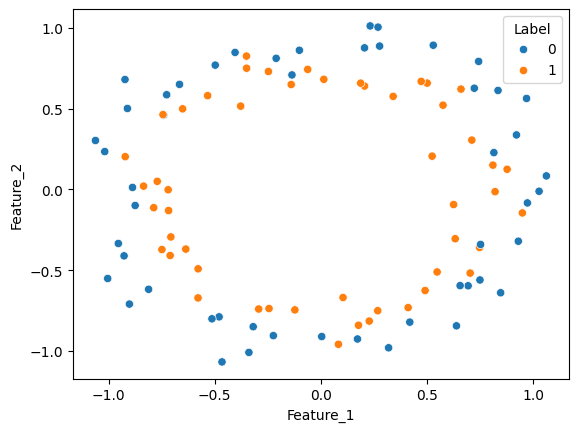

In [7]:
import seaborn as sns

sns.scatterplot(data=df, x='Feature_1', y='Feature_2', hue='Label')

# In data visualization, particularly in libraries like Seaborn and Matplotlib, hue refers to a categorical variable 
# that is used to represent different groups or classes in a dataset by coloring the data points differently. 
# It helps to distinguish between different categories visually, enhancing the interpretability of the plot.

In [8]:
# Train test split

from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 2)

# Taking nump array 'x' and 'y'

In [9]:
x_train.shape

(80, 2)

In [10]:
model = Sequential()

model.add(Dense(256, input_dim = 2, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

In [11]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [12]:
history = model.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 3500)

Epoch 1/3500
3/3 [==============================] - 1s 183ms/step - loss: 0.6952 - accuracy: 0.4625 - val_loss: 0.6782 - val_accuracy: 0.5500
Epoch 2/3500
3/3 [==============================] - 0s 19ms/step - loss: 0.6918 - accuracy: 0.4875 - val_loss: 0.6818 - val_accuracy: 0.5500
Epoch 3/3500
3/3 [==============================] - 0s 25ms/step - loss: 0.6899 - accuracy: 0.4875 - val_loss: 0.6861 - val_accuracy: 0.5500
Epoch 4/3500
3/3 [==============================] - 0s 31ms/step - loss: 0.6880 - accuracy: 0.4875 - val_loss: 0.6905 - val_accuracy: 0.5500
Epoch 5/3500
3/3 [==============================] - 0s 33ms/step - loss: 0.6862 - accuracy: 0.5125 - val_loss: 0.6943 - val_accuracy: 0.5500
Epoch 6/3500
3/3 [==============================] - 0s 32ms/step - loss: 0.6849 - accuracy: 0.5375 - val_loss: 0.6984 - val_accuracy: 0.4500
Epoch 7/3500
3/3 [==============================] - 0s 28ms/step - loss: 0.6839 - accuracy: 0.5625 - val_loss: 0.7024 - val_accuracy: 0.4500
Epoch 8/3500

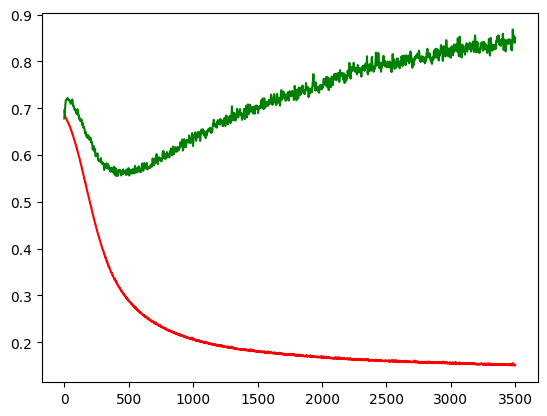

In [14]:
# Let's plot the training and val loss and understand the concept of optimal epochs.

import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label = 'Training loss', color = 'red')
plt.plot(history.history['val_loss'], label = 'Val loss',  color = 'green')

# Leave this file and go to colab in email id `nikunjbos26@gmail.com`